<a href="https://colab.research.google.com/github/kalyanisundarams93/Python/blob/main/Data_Visualization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Problem Statement**  
Taxi services generate large amounts of trip data daily, which can be used to understand patterns and improve operations. However, raw data often contains missing values and is difficult to interpret without proper analysis.  
In this project, you will act as a data analyst to clean, analyze, and visualize taxi data. You will handle missing values, explore trends, and create visualizations to gain insights into fare, distance, and customer behavior using Pandas, Matplotlib, and Seaborn.

1) Loading the Taxis Dataset using the following code:  
import seaborn as sns  
Load the 'taxis' dataset  
df = sns.load_dataset("taxis")  

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
df = sns.load_dataset("taxis")

2) Handling Missing Values  
● Check for missing values in the dataset and identify columns with missing data.  
● Impute missing values using appropriate strategies based on the column type (e.g., using the mean, median, or mode for numerical columns and the mode for categorical columns).  
● For columns that are critical and cannot be reasonably imputed, remove rows with missing values to maintain data integrity.

In [ ]:
# Check for missing values in the dataset and identify columns with missing data.
print(df.head(2))
print(df.tail(2))
print(df.shape)
df.info()

               pickup             dropoff  passengers  distance  fare   tip  \
0 2019-03-23 20:21:09 2019-03-23 20:27:24           1      1.60   7.0  2.15   
1 2019-03-04 16:11:55 2019-03-04 16:19:00           1      0.79   5.0  0.00   

   tolls  total   color      payment            pickup_zone  \
0    0.0  12.95  yellow  credit card        Lenox Hill West   
1    0.0   9.30  yellow         cash  Upper West Side South   

            dropoff_zone pickup_borough dropoff_borough  
0    UN/Turtle Bay South      Manhattan       Manhattan  
1  Upper West Side South      Manhattan       Manhattan  
                  pickup             dropoff  passengers  distance  fare  \
6431 2019-03-04 10:09:25 2019-03-04 10:14:29           1      1.12   6.0   
6432 2019-03-13 19:31:22 2019-03-13 19:48:02           1      3.85  15.0   

       tip  tolls  total  color      payment    pickup_zone  \
6431  0.00    0.0   6.80  green  credit card  East New York   
6432  3.36    0.0  20.16  green  credit car

In [ ]:
# Impute missing values using appropriate strategies based on the column type
# (e.g., using the mean, median, or mode for numerical columns and the mode for categorical columns).

df['payment'] = df['payment'].fillna(df['payment'].mode()[0])
df['pickup_zone'] = df['pickup_zone'].fillna(df['pickup_zone'].mode()[0])
df['dropoff_zone'] = df['dropoff_zone'].fillna(df['dropoff_zone'].mode()[0])
df['pickup_borough'] = df['pickup_borough'].fillna(df['pickup_borough'].mode()[0])
df['dropoff_borough'] = df['dropoff_borough'].fillna(df['dropoff_borough'].mode()[0])
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6433 entries, 0 to 6432
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   pickup           6433 non-null   datetime64[ns]
 1   dropoff          6433 non-null   datetime64[ns]
 2   passengers       6433 non-null   int64         
 3   distance         6433 non-null   float64       
 4   fare             6433 non-null   float64       
 5   tip              6433 non-null   float64       
 6   tolls            6433 non-null   float64       
 7   total            6433 non-null   float64       
 8   color            6433 non-null   object        
 9   payment          6433 non-null   object        
 10  pickup_zone      6433 non-null   object        
 11  dropoff_zone     6433 non-null   object        
 12  pickup_borough   6433 non-null   object        
 13  dropoff_borough  6433 non-null   object        
dtypes: datetime64[ns](2), float64(5), int64(

**3) Visualizations using Matplotlib/Pandas Plot:**

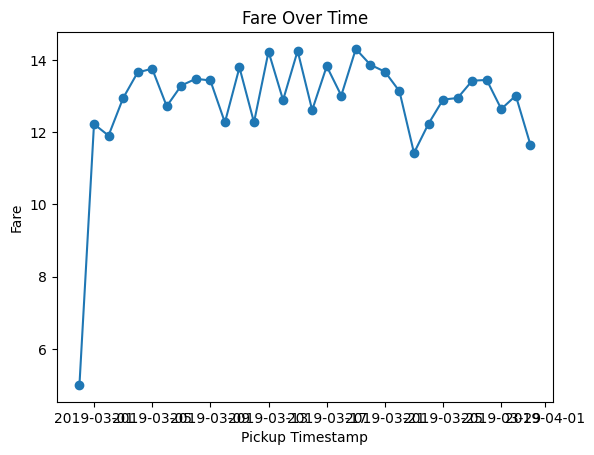

In [21]:
# Line Chart
# Plot a line chart to visualize the fare over time, using the pickup timestamp as the x-axis and fare as the y-axis.
# Ensure the pickup column is converted to a datetime format before plotting.

df['pickup'] = pd.to_datetime(df['pickup'])
# Group by date and calculate average fare
daily_fare = df.groupby(df['pickup'].dt.date)['fare'].mean()

plt.plot(daily_fare.index, daily_fare.values, marker='o')

plt.title("Fare Over Time")
plt.xlabel("Pickup Timestamp")
plt.ylabel("Fare")
plt.show()

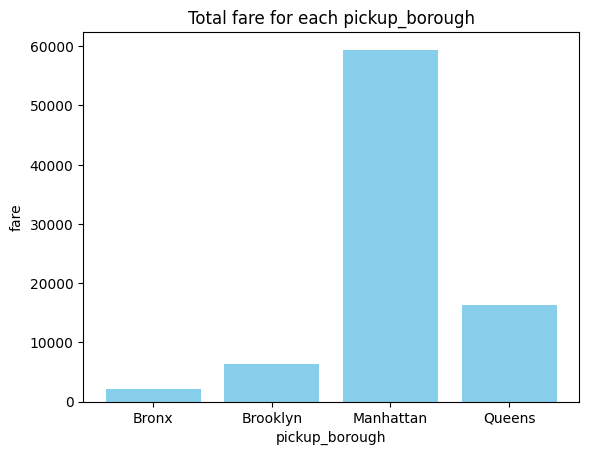

In [ ]:
# Bar Chart
# Create a bar chart to show the total fare for each pickup_borough.
# Group the data by pickup_borough and sum the fare for each group.

total_fare = df.groupby('pickup_borough')['fare'].sum()

plt.bar(total_fare.index, total_fare.values, color = 'skyblue')

plt.title('Total fare for each pickup_borough')
plt.xlabel('pickup_borough')
plt.ylabel('fare')
plt.show()

payment
credit card    4621
cash           1812
Name: count, dtype: int64


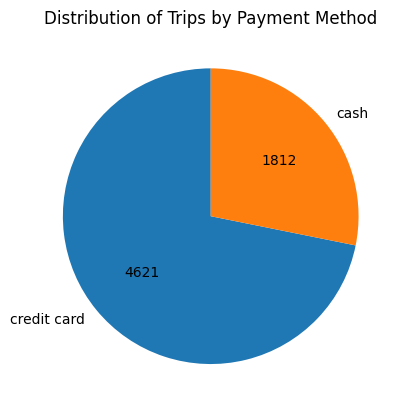

In [ ]:
# Pie Chart
# Plot a pie chart showing the distribution of trips based on the payment method (credit card, cash, etc.).
# Each slice should represent the count of trips for a specific payment method.
payment_counts = df['payment'].value_counts()
print(payment_counts)
def show_count(pct):
    total = payment_counts.sum()
    count = int(round(pct * total / 100))
    return count

plt.pie(
    payment_counts.values,
    labels=payment_counts.index,
    autopct=show_count,
    startangle=90
)
plt.title('Distribution of Trips by Payment Method')
plt.show()

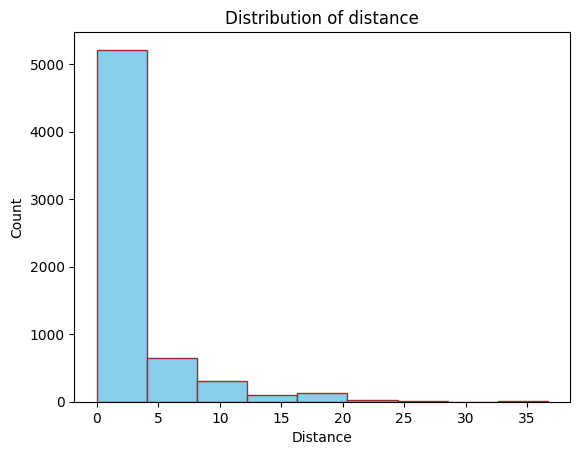

In [ ]:
# Histogram
# Create a histogram to visualize the distribution of distance.
# Customize the number of bins for better granularity and ensure the plot is easy to interpret.

plt.hist(df['distance'], bins=9, color='skyblue', edgecolor='brown')
plt.title("Distribution of distance")
plt.xlabel("Distance")
plt.ylabel("Count")

plt.show()


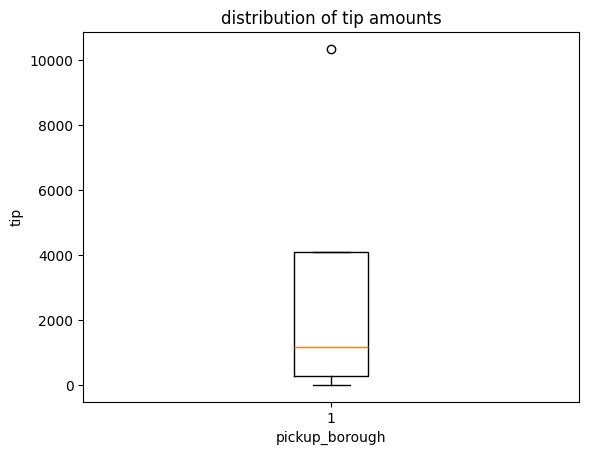

In [ ]:
# Box Plot
# Plot a box plot to visualize the distribution of tip amounts for each pickup_borough.
# Use pickup_borough as the categorical axis and tip as the numeric axis.

total_tip = df.groupby('pickup_borough')['tip'].sum()

plt.boxplot(total_tip.values)
plt.title("distribution of tip amounts")
plt.xlabel("pickup_borough")
plt.ylabel("tip")

plt.show()

**Visualizations using Seaborn:**

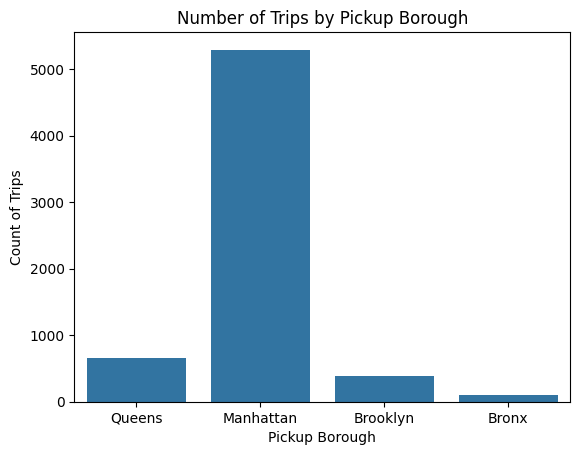

In [ ]:
# Count Plot
# Create a count plot to visualize the number of trips in each pickup_borough.
# The x-axis should represent the boroughs, and the y-axis should show the count of trips

sns.countplot(data=df, x='pickup_borough')

plt.title("Number of Trips by Pickup Borough")
plt.xlabel("Pickup Borough")
plt.ylabel("Count of Trips")

plt.show()


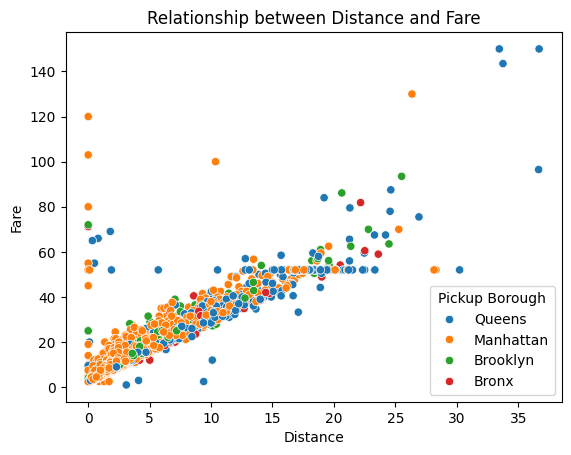

In [ ]:
# Scatter Plot
# Plot a scatter plot to show the relationship between distance and fare. Use distance on the x-axis and fare on the y-axis to visualize any correlation.
# Color the points based on the pickup_borough to differentiate the trips by their respective boroughs.

sns.scatterplot(data=df, x='distance', y='fare', hue='pickup_borough')

plt.title("Relationship between Distance and Fare")
plt.xlabel("Distance")
plt.ylabel("Fare")
plt.legend(title="Pickup Borough")

plt.show()

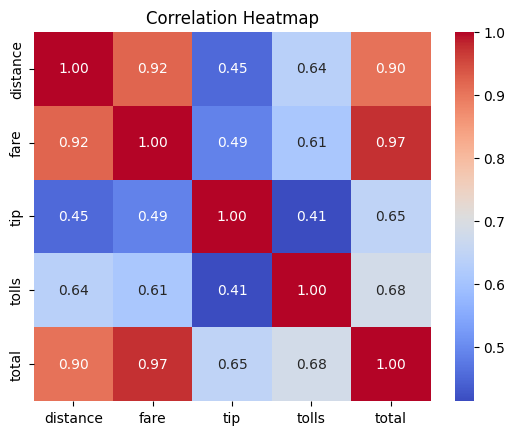

In [ ]:
# Heatmap
# Plot a heatmap to visualize the correlation between numerical variables such as distance, fare, tip, tolls, and total.
# Use a correlation matrix to highlight the relationships.
cols = ['distance', 'fare', 'tip', 'tolls', 'total']

corr_matrix = df[cols].corr()

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f')

plt.title("Correlation Heatmap")
plt.show()

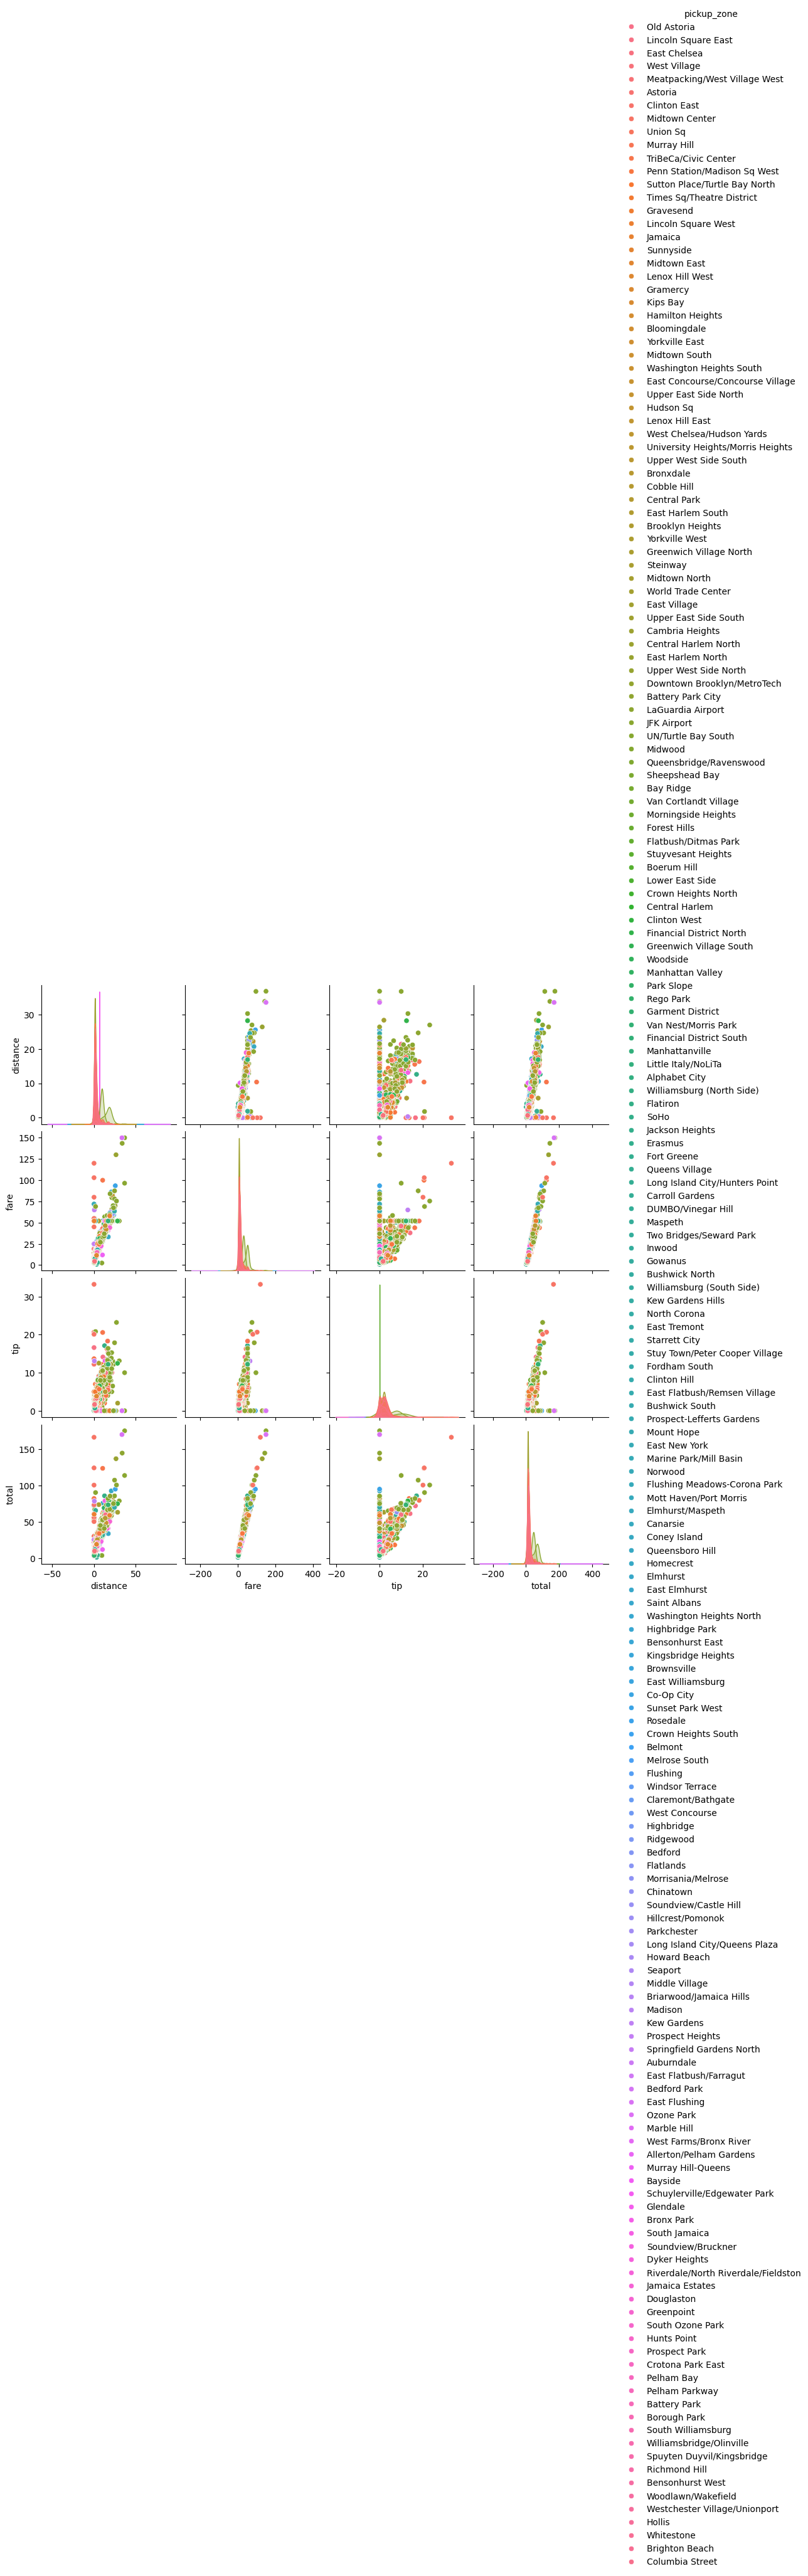

In [ ]:
# Pair Plot
# Create a pair plot to visualize the pairwise relationships between distance, fare, tip, and total.
# Color the data points according to the pickup_zone column. to compare how different zones affect these variables.

cols1 = ['distance', 'fare', 'tip', 'total', 'pickup_zone']

sns.pairplot(df[cols1], hue='pickup_zone')

plt.show()

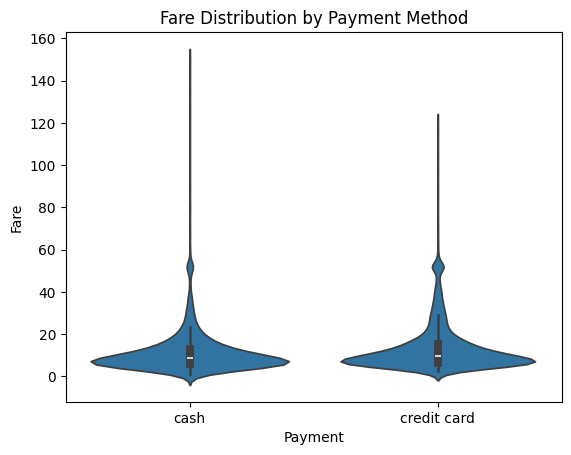

In [ ]:
# Plot a violin plot to show the distribution of fare for each payment method.
# Use the payment method as the categorical axis and fare as the numeric axis to visualize its distribution.

sns.violinplot(data=df, x='payment', y='fare')

plt.title("Fare Distribution by Payment Method")
plt.xlabel("Payment")
plt.ylabel("Fare")

plt.show()